# EU imports by transport mode

**What this notebook does.** It reads the Comext extra-EU import data (the same HS-6 codes as the US case analyses), aggregated across EU reporters by partner and transport mode, and shows how the mode split changed over time. The US cases found that chokepoint disruptions barely moved the air share for the gear's Asian supply; this checks whether the EU's modal mix tells a different story, given the shorter sea routes through Suez.

**To run:** set `ANALYST_DATABASE_URL` in `analysis/.env`, then run all cells. It reads; it never writes to the database.

## 1. Setup

In [1]:
import matplotlib.pyplot as plt
import polars as pl

from shockt_analysis import core
from shockt_analysis.settings import get_settings

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(140)
pl.Config.set_float_precision(4)

GEAR = ["850421", "850422", "850423", "850433", "850434", "853720"]
SERVERS = ["847150"]
ALL_CODES = GEAR + SERVERS
MODE_COLORS = {
    "sea": "#2d5b4f",
    "air": "#a2412d",
    "road": "#c98a2b",
    "rail": "#5b7da2",
    "inland_waterway": "#8a9a8f",
    "other": "#bbbbbb",
}

In [2]:
with core.connect(get_settings()) as conn:
    eu = core.eu_imports(conn, ALL_CODES)
    loads = core.current_loads(conn, ["comext_trade"])

print(f"Rows: {eu.height:,}")
print(f"Months: {eu['month'].min()} to {eu['month'].max()}")
print(f"Partners: {eu['partner'].n_unique()}")
print(f"HS-6 codes: {sorted(eu['hs6'].unique().to_list())}")
loads

Rows: 6,621
Months: 2022-01-01 to 2024-12-01
Partners: 39
HS-6 codes: ['847150', '850421', '850422', '850423', '850433', '850434', '853720']


dataset,partitions,latest_load,code_versions
str,i64,str,str
"""comext_trade""",252,"""2026-10-24 13:53:02.205859+00""","""1f10182, 9ed641f-dirty"""


## 2. Overall mode split over time

Monthly share of total import quantity (kg) by transport mode, all partners and codes combined.

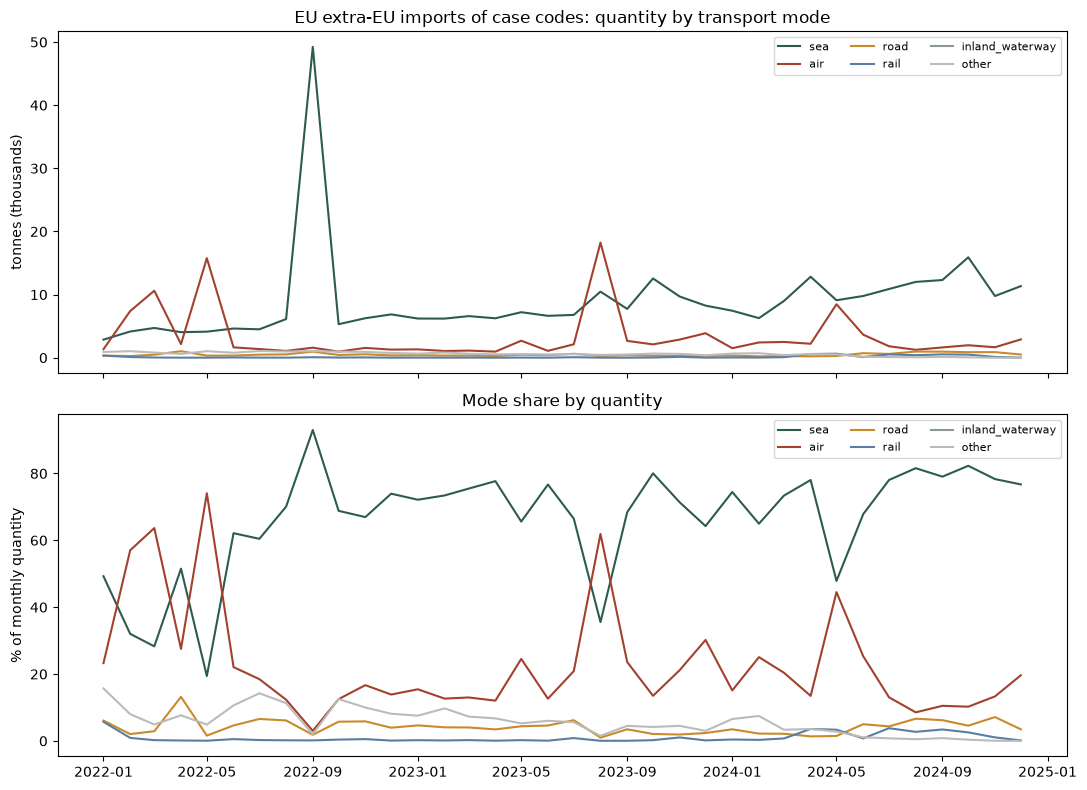

In [3]:
monthly_mode = (
    eu.group_by("month", "transport_mode")
    .agg(pl.col("quantity_kg").sum())
    .with_columns(
        (pl.col("quantity_kg") / pl.col("quantity_kg").sum().over("month")).alias("share")
    )
    .sort("month")
)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
for mode, color in MODE_COLORS.items():
    part = monthly_mode.filter(pl.col("transport_mode") == mode)
    if part.height == 0:
        continue
    ax1.plot(part["month"].to_list(), (part["quantity_kg"] / 1e6).to_list(),
             label=mode, color=color)
    ax2.plot(part["month"].to_list(), (part["share"] * 100).to_list(),
             label=mode, color=color)
ax1.set_ylabel("tonnes (thousands)")
ax1.set_title("EU extra-EU imports of case codes: quantity by transport mode")
ax1.legend(fontsize=8, ncols=3)
ax2.set_ylabel("% of monthly quantity")
ax2.set_title("Mode share by quantity")
ax2.legend(fontsize=8, ncols=3)
plt.tight_layout()
plt.show()

## 3. Mode split: gear vs servers

The gear codes (transformers, switchgear) and servers may have different modal profiles. Gear is heavy and shipped mainly by sea; servers have high value density and a higher air share.

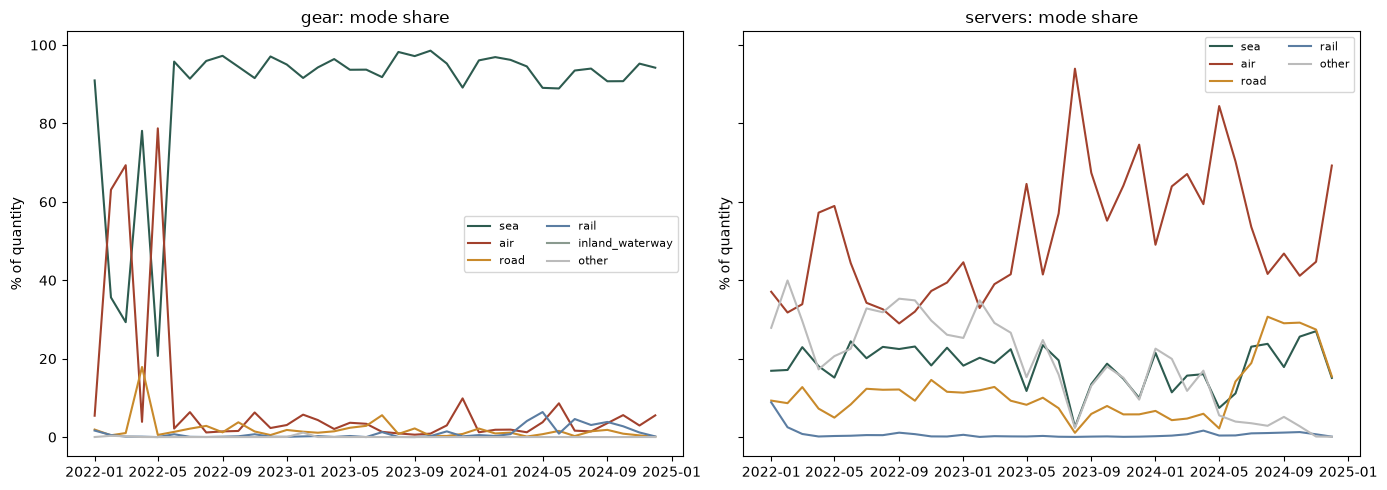

In [4]:
eu_tagged = eu.with_columns(
    pl.when(pl.col("hs6").is_in(GEAR))
    .then(pl.lit("gear"))
    .otherwise(pl.lit("servers"))
    .alias("product_group")
)

group_mode = (
    eu_tagged.group_by("month", "product_group", "transport_mode")
    .agg(pl.col("quantity_kg").sum())
    .with_columns(
        (pl.col("quantity_kg") / pl.col("quantity_kg").sum().over("month", "product_group"))
        .alias("share")
    )
    .sort("month")
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, group in zip(axes, ["gear", "servers"], strict=True):
    part = group_mode.filter(pl.col("product_group") == group)
    for mode, color in MODE_COLORS.items():
        mp = part.filter(pl.col("transport_mode") == mode)
        if mp.height == 0:
            continue
        ax.plot(mp["month"].to_list(), (mp["share"] * 100).to_list(),
                label=mode, color=color)
    ax.set_ylabel("% of quantity")
    ax.set_title(f"{group}: mode share")
    ax.legend(fontsize=8, ncols=2)
plt.tight_layout()
plt.show()

## 4. Top partners by sea and air

Which extra-EU partners supply the most by sea, and which by air. This surfaces the same Asian origins the US cases track (China, Korea, Taiwan) plus any EU-specific patterns (Turkey, UK, Norway by road or sea).

In [5]:
partner_mode = (
    eu.group_by("partner", "transport_mode")
    .agg(pl.col("quantity_kg").sum(), pl.col("value_eur").sum())
    .sort("quantity_kg", descending=True)
)

print("Top 10 partners by sea quantity:")
sea_top = partner_mode.filter(pl.col("transport_mode") == "sea").head(10)
print(sea_top)

print("\nTop 10 partners by air quantity:")
air_top = partner_mode.filter(pl.col("transport_mode") == "air").head(10)
print(air_top)

print("\nTop 10 partners by road quantity:")
road_top = partner_mode.filter(pl.col("transport_mode") == "road").head(10)
print(road_top)

Top 10 partners by sea quantity:
shape: (10, 4)
┌─────────┬────────────────┬────────────────┬─────────────────┐
│ partner ┆ transport_mode ┆ quantity_kg    ┆ value_eur       │
│ ---     ┆ ---            ┆ ---            ┆ ---             │
│ str     ┆ str            ┆ f64            ┆ f64             │
╞═════════╪════════════════╪════════════════╪═════════════════╡
│ CN      ┆ sea            ┆ 234996694.0000 ┆ 3247204120.0000 │
│ IN      ┆ sea            ┆ 43465570.0000  ┆ 244514610.0000  │
│ LB      ┆ sea            ┆ 26918271.0000  ┆ 160223668.0000  │
│ KR      ┆ sea            ┆ 7460060.0000   ┆ 81823230.0000   │
│ AE      ┆ sea            ┆ 1753869.0000   ┆ 15461895.0000   │
│ HK      ┆ sea            ┆ 1701389.0000   ┆ 18158988.0000   │
│ SA      ┆ sea            ┆ 1608922.0000   ┆ 11182135.0000   │
│ VN      ┆ sea            ┆ 1419392.0000   ┆ 44149380.0000   │
│ TW      ┆ sea            ┆ 1226164.0000   ┆ 319349207.0000  │
│ JP      ┆ sea            ┆ 864844.0000    ┆ 49486966.0

## 5. Asian partners: mode split over time

The same partners the US cases track, filtered to the ones present in the EU data. Their sea routes from Asia to Europe pass through Suez (or around the Cape), so the Red Sea disruption hits them directly.

Asian rows: 3,194, partners present: ['CN', 'IN', 'JP', 'KR', 'TW', 'VN']


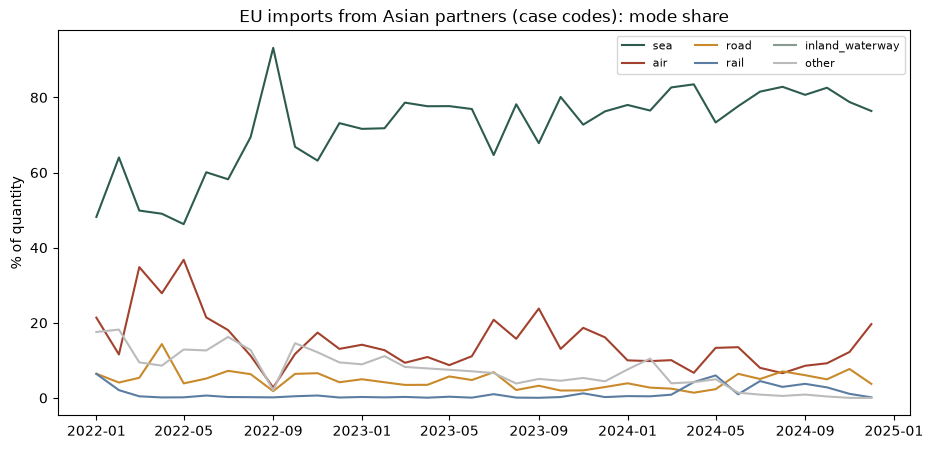

In [6]:
ASIAN_PARTNERS = ["CN", "KR", "TW", "VN", "IN", "JP"]
asian = eu.filter(pl.col("partner").is_in(ASIAN_PARTNERS))
partners_present = sorted(asian["partner"].unique().to_list())
print(f"Asian rows: {asian.height:,}, partners present: {partners_present}")

asian_monthly = (
    asian.group_by("month", "transport_mode")
    .agg(pl.col("quantity_kg").sum())
    .with_columns(
        (pl.col("quantity_kg") / pl.col("quantity_kg").sum().over("month")).alias("share")
    )
    .sort("month")
)

fig, ax = plt.subplots(figsize=(11, 5))
for mode, color in MODE_COLORS.items():
    part = asian_monthly.filter(pl.col("transport_mode") == mode)
    if part.height == 0:
        continue
    ax.plot(part["month"].to_list(), (part["share"] * 100).to_list(),
            label=mode, color=color)
ax.set_ylabel("% of quantity")
ax.set_title("EU imports from Asian partners (case codes): mode share")
ax.legend(fontsize=8, ncols=3)
plt.show()

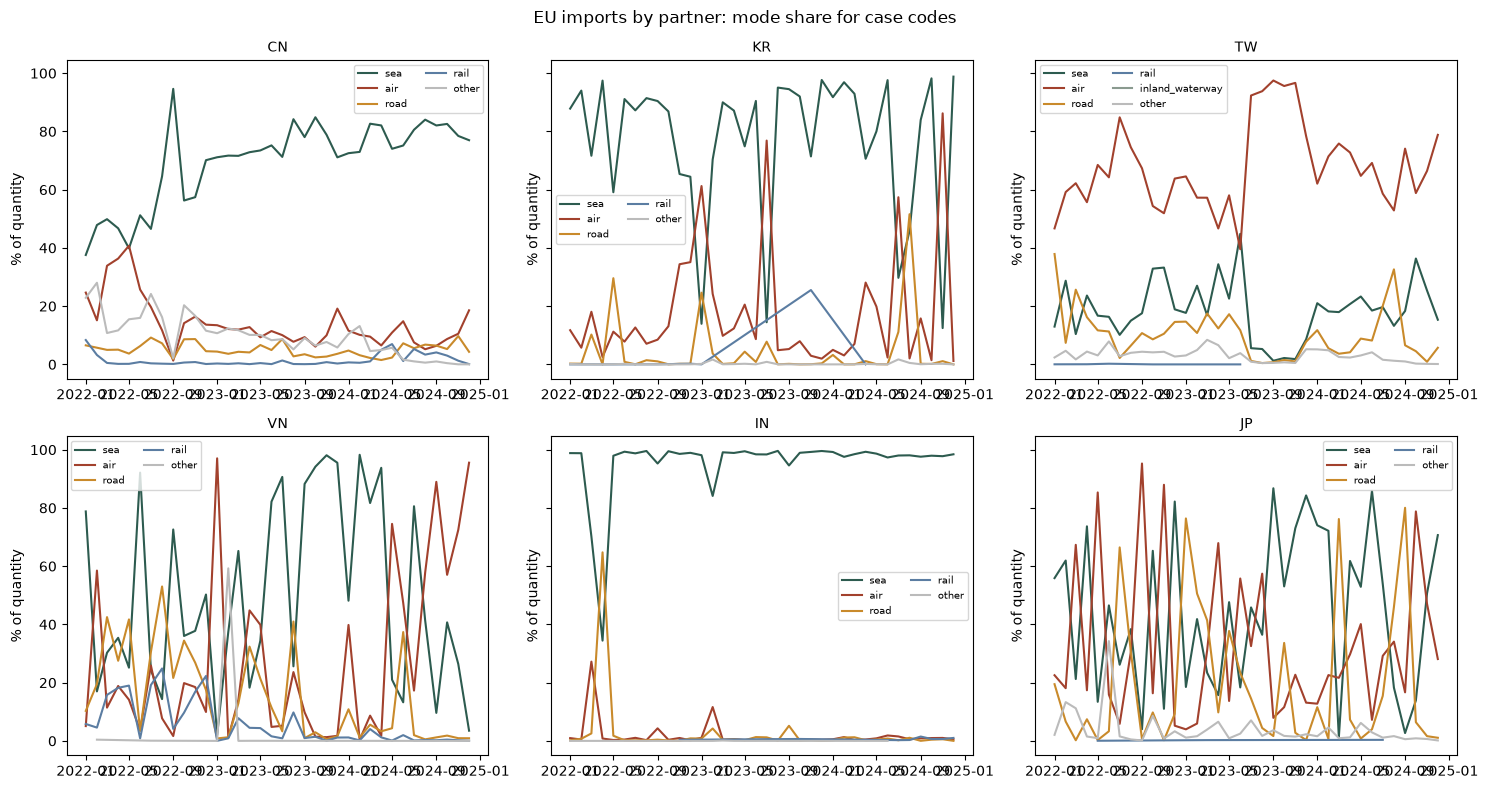

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for ax, partner in zip(axes.flat, ASIAN_PARTNERS, strict=True):
    pdata = (
        asian.filter(pl.col("partner") == partner)
        .group_by("month", "transport_mode")
        .agg(pl.col("quantity_kg").sum())
        .with_columns(
            (pl.col("quantity_kg") / pl.col("quantity_kg").sum().over("month")).alias("share")
        )
        .sort("month")
    )
    for mode, color in MODE_COLORS.items():
        mp = pdata.filter(pl.col("transport_mode") == mode)
        if mp.height == 0:
            continue
        ax.plot(mp["month"].to_list(), (mp["share"] * 100).to_list(),
                label=mode, color=color)
    ax.set_title(partner, fontsize=10)
    ax.set_ylabel("% of quantity")
    ax.legend(fontsize=7, ncols=2)
plt.suptitle("EU imports by partner: mode share for case codes", fontsize=12)
plt.tight_layout()
plt.show()

## 6. Sea vs air tonnage from Asia, absolute

The share chart hides volume changes. This shows the absolute tonnage by sea and air from the Asian partners, so a shift from sea to air shows both as levels.

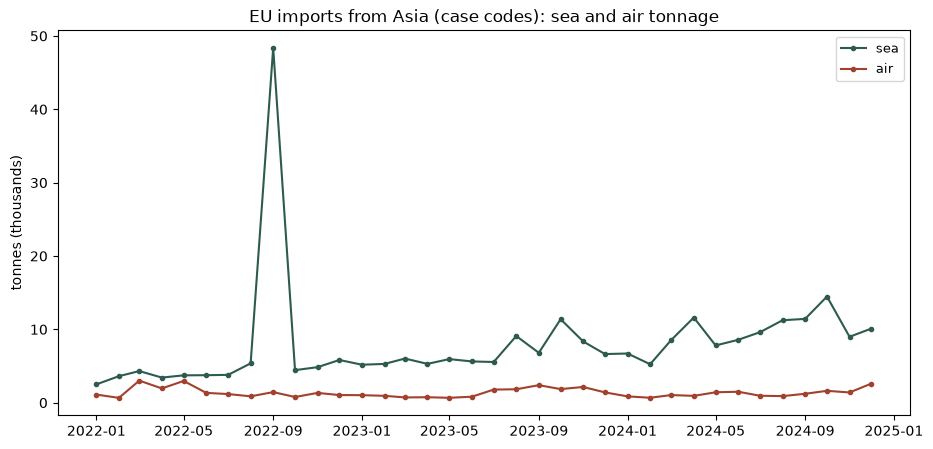

In [8]:
sea_air = asian_monthly.filter(pl.col("transport_mode").is_in(["sea", "air"]))

fig, ax = plt.subplots(figsize=(11, 5))
for mode, color in [("sea", "#2d5b4f"), ("air", "#a2412d")]:
    part = sea_air.filter(pl.col("transport_mode") == mode)
    ax.plot(part["month"].to_list(), (part["quantity_kg"] / 1e6).to_list(),
            label=mode, color=color, marker=".")
ax.set_ylabel("tonnes (thousands)")
ax.set_title("EU imports from Asia (case codes): sea and air tonnage")
ax.legend(fontsize=9)
plt.show()

## 7. Summary statistics by half-year

Mode shares averaged over half-year periods, for comparison with the US case windows.

In [9]:
asian_half = (
    asian.with_columns(
        pl.date(
            pl.col("month").dt.year(),
            ((pl.col("month").dt.month() - 1) // 6) * 6 + 1,
            1,
        ).alias("half")
    )
    .group_by("half", "transport_mode")
    .agg(pl.col("quantity_kg").sum())
    .with_columns(
        (pl.col("quantity_kg") / pl.col("quantity_kg").sum().over("half")).alias("share")
    )
    .sort("half")
)

half_table = asian_half.pivot(on="transport_mode", index="half", values="share")
half_table

half,air,sea,rail,road,other,inland_waterway
date,f64,f64,f64,f64,f64,f64
2022-01-01,0.2704,0.5234,0.0135,0.0654,0.1273,null
2022-07-01,0.0751,0.8216,0.0023,0.0359,0.0652,null
2023-01-01,0.1114,0.7574,0.0020,0.0445,0.0847,null
2023-07-01,0.1765,0.7399,0.0046,0.0298,0.0491,null
2024-01-01,0.1045,0.7900,0.0244,0.0315,0.0496,null
2024-07-01,0.1062,0.8062,0.0258,0.0570,0.0047,0.0002


## 8. Findings

In [10]:
total_sea = sea_air.filter(pl.col("transport_mode") == "sea")["quantity_kg"].sum()
total_air = sea_air.filter(pl.col("transport_mode") == "air")["quantity_kg"].sum()
sea_share = total_sea / (total_sea + total_air) * 100
air_share = total_air / (total_sea + total_air) * 100

partners_present = sorted(asian["partner"].unique().to_list())
months_range = f"{eu['month'].min()} to {eu['month'].max()}"

findings = [
    f"Comext covers {eu['month'].n_unique()} months ({months_range}), "
    f"{eu['partner'].n_unique()} extra-EU partners, {len(ALL_CODES)} HS-6 codes.",
    f"Asian partners present: {', '.join(partners_present)}.",
    f"Across the full period, sea accounts for {sea_share:.1f}% and air for {air_share:.1f}% "
    f"of the case codes' Asian import quantity to the EU (by weight).",
]
for f in findings:
    print("-", f)

- Comext covers 36 months (2022-01-01 to 2024-12-01), 39 extra-EU partners, 7 HS-6 codes.
- Asian partners present: CN, IN, JP, KR, TW, VN.
- Across the full period, sea accounts for 85.5% and air for 14.5% of the case codes' Asian import quantity to the EU (by weight).
